# 🛡️ OIBSIP Task 4: Email / SMS Spam Detection Using Machine Learning
### **OASIS INFOBYTE Data Science Internship — Task 4**
**Author:** Data Science Intern  
**Date:** November 2026  
**Environment:** Python 3.14 | Scikit-Learn | NLTK | Pandas | Seaborn  

---

## 📌 1. Project Introduction
Electronic spam messages present significant security, privacy, and operational risks, ranging from commercial unsolicited advertising to malicious phishing campaigns, credential harvesting, and financial fraud. Automated text classification leveraging Natural Language Processing (NLP) and supervised machine learning provides a scalable, algorithmic defense mechanism to identify and quarantine spam while ensuring that legitimate communications (*ham*) reach user inboxes uninterrupted.

## 🎯 2. Project Objective
The primary objective of this project is to develop, evaluate, and benchmark an end-to-end NLP binary classification system that accurately distinguishes between:
* **Spam (1):** Unsolicited, commercial, or deceptive promotional messages.
* **Ham (0):** Legitimate personal or institutional messages.

### Key Milestones:
1. Ingest and audit the authentic **Kaggle SMS Spam Collection dataset**.
2. Clean and preprocess raw text (lowercasing, punctuation stripping, URL/email removal, stopword filtering, and Porter stemming).
3. Extract numerical feature vectors using **TF-IDF (Term Frequency - Inverse Document Frequency)** with unigrams and bigrams.
4. Train and benchmark two complementary classification algorithms:
   * **Multinomial Naive Bayes (MNB)**
   * **Logistic Regression (LR)**
5. Prevent data leakage by fitting vectorizers and scalers strictly on training partitions via Scikit-Learn `Pipeline` architectures.
6. Evaluate models comprehensively using Accuracy, Precision, Recall, F1-Score, and Confusion Matrices.
7. Conduct an in-depth analytical discussion on the operational trade-off between **Precision** and **Recall**.
8. Test arbitrary user-defined messages in real-time inference.

## 🌐 3. Dataset Information & Clarification
* **Dataset Name:** SMS Spam Collection Dataset
* **Source:** [Kaggle SMS Spam Collection Dataset (UCI ML Repository)](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset)
* **Authors / Donors:** Tiago A. Almeida and José María Gómez Hidalgo
* **Dataset Format:** CSV with 5,572 records.
* **Original Columns:** `v1` (Class Label), `v2` (Message Text), and three empty auxiliary columns (`Unnamed: 2`, `Unnamed: 3`, `Unnamed: 4`).

> **⚠️ Important Dataset Clarification:**  
> While this internship task is framed as *Email Spam Detection*, the canonical open benchmark dataset used across academia and industry is the **SMS Spam Collection**. Short Message Service (SMS) texts are characterized by compact length, frequent abbreviations, phonetic spelling, and promotional urgency (e.g., *"Claim free prize"*, *"Call now"*). The core NLP preprocessing, TF-IDF feature extraction, and Bayesian/logistic modeling methodologies demonstrated here translate directly to standard email spam filtering pipelines.

## 📦 4. Library Imports & Environment Configuration
We import standard data science, visualization, NLP, and machine learning libraries.

In [1]:
import os
import sys
import re
import string
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Components
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# NLTK & WordCloud
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from wordcloud import WordCloud

# Configure plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 0.8

# Configure local NLTK data path if available
PROJECT_DIR = os.path.dirname(os.path.abspath(os.getcwd())) if 'notebooks' in os.getcwd() else os.getcwd()
NLTK_LOCAL = os.path.join(PROJECT_DIR, "nltk_data")
if os.path.exists(NLTK_LOCAL):
    nltk.data.path.append(NLTK_LOCAL)

warnings.filterwarnings('ignore')
print("✅ Libraries successfully imported.")

✅ Libraries successfully imported.


## 📂 5. Dataset Loading
The raw CSV file uses `latin-1` (ISO-8859-1) character encoding. We load the raw file from `dataset/spam.csv`.

In [2]:
# Locate dataset
DATA_PATH = os.path.join(PROJECT_DIR, "dataset", "spam.csv")
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join("..", "dataset", "spam.csv")

df_raw = pd.read_csv(DATA_PATH, encoding="latin-1")
print(f"✅ Raw Dataset successfully loaded from: {DATA_PATH}")
print(f"📊 Dataset Shape: {df_raw.shape[0]:,d} rows × {df_raw.shape[1]} columns")
df_raw.head()

✅ Raw Dataset successfully loaded from: C:\Users\ASUS\Desktop\OIBSIP\OIBSIP_Task4_Spam_Detection\dataset\spam.csv
📊 Dataset Shape: 5,572 rows × 5 columns


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## 🔍 6. Data Inspection & Hygiene Audit
We examine columns, drop the three empty trailing columns (`Unnamed: 2`, `Unnamed: 3`, `Unnamed: 4`), rename `v1` to `label` and `v2` to `message`, check data types, missing values, duplicates, and class balance.

In [3]:
# Retain primary columns and rename
df = df_raw[["v1", "v2"]].copy()
df.rename(columns={"v1": "label", "v2": "message"}, inplace=True)

# Add binary target (ham = 0, spam = 1)
df["target"] = df["label"].map({"ham": 0, "spam": 1})

# Data Overview
print("=== DATASET OVERVIEW ===")
print(df.info())
print("\n=== MISSING VALUES ANALYSIS ===")
print(df.isnull().sum())
print(f"\nExact duplicate messages: {df.duplicated(subset=['message']).sum():,d}")

# Class Counts & Proportions
class_counts = df["label"].value_counts()
class_pcts = (df["label"].value_counts(normalize=True) * 100).round(2)

summary_table = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_pcts
})
print("\n=== CLASS DISTRIBUTION ===")
print(summary_table)

=== DATASET OVERVIEW ===
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
 2   target   5572 non-null   int64
dtypes: int64(1), str(2)
memory usage: 584.9 KB
None

=== MISSING VALUES ANALYSIS ===
label      0
message    0
target     0
dtype: int64

Exact duplicate messages: 403

=== CLASS DISTRIBUTION ===
       Count  Percentage (%)
label                       
ham     4825           86.59
spam     747           13.41


## 📊 7. Exploratory Data Analysis (EDA)
We analyze message length characteristics, character distributions, word frequencies, and class balance.

In [4]:
# Engineer character and word counts for EDA
df["char_count"] = df["message"].apply(len)
df["word_count"] = df["message"].apply(lambda x: len(x.split()))

print("=== MESSAGE LENGTH DESCRIPTIVE STATISTICS (BY CLASS) ===")
print(df.groupby("label")[["char_count", "word_count"]].describe().T)

=== MESSAGE LENGTH DESCRIPTIVE STATISTICS (BY CLASS) ===
label                     ham        spam
char_count count  4825.000000  747.000000
           mean     71.023627  138.866131
           std      58.016023   29.183082
           min       2.000000   13.000000
           25%      33.000000  132.500000
           50%      52.000000  149.000000
           75%      92.000000  157.000000
           max     910.000000  224.000000
word_count count  4825.000000  747.000000
           mean     14.200622   23.851406
           std      11.424511    5.811898
           min       1.000000    2.000000
           25%       7.000000   22.000000
           50%      11.000000   25.000000
           75%      19.000000   28.000000
           max     171.000000   35.000000


### 7.1 Visualizing Class Distribution (Count Plot & Pie Chart)

findfont: Failed to find font weight 600, now using 700.


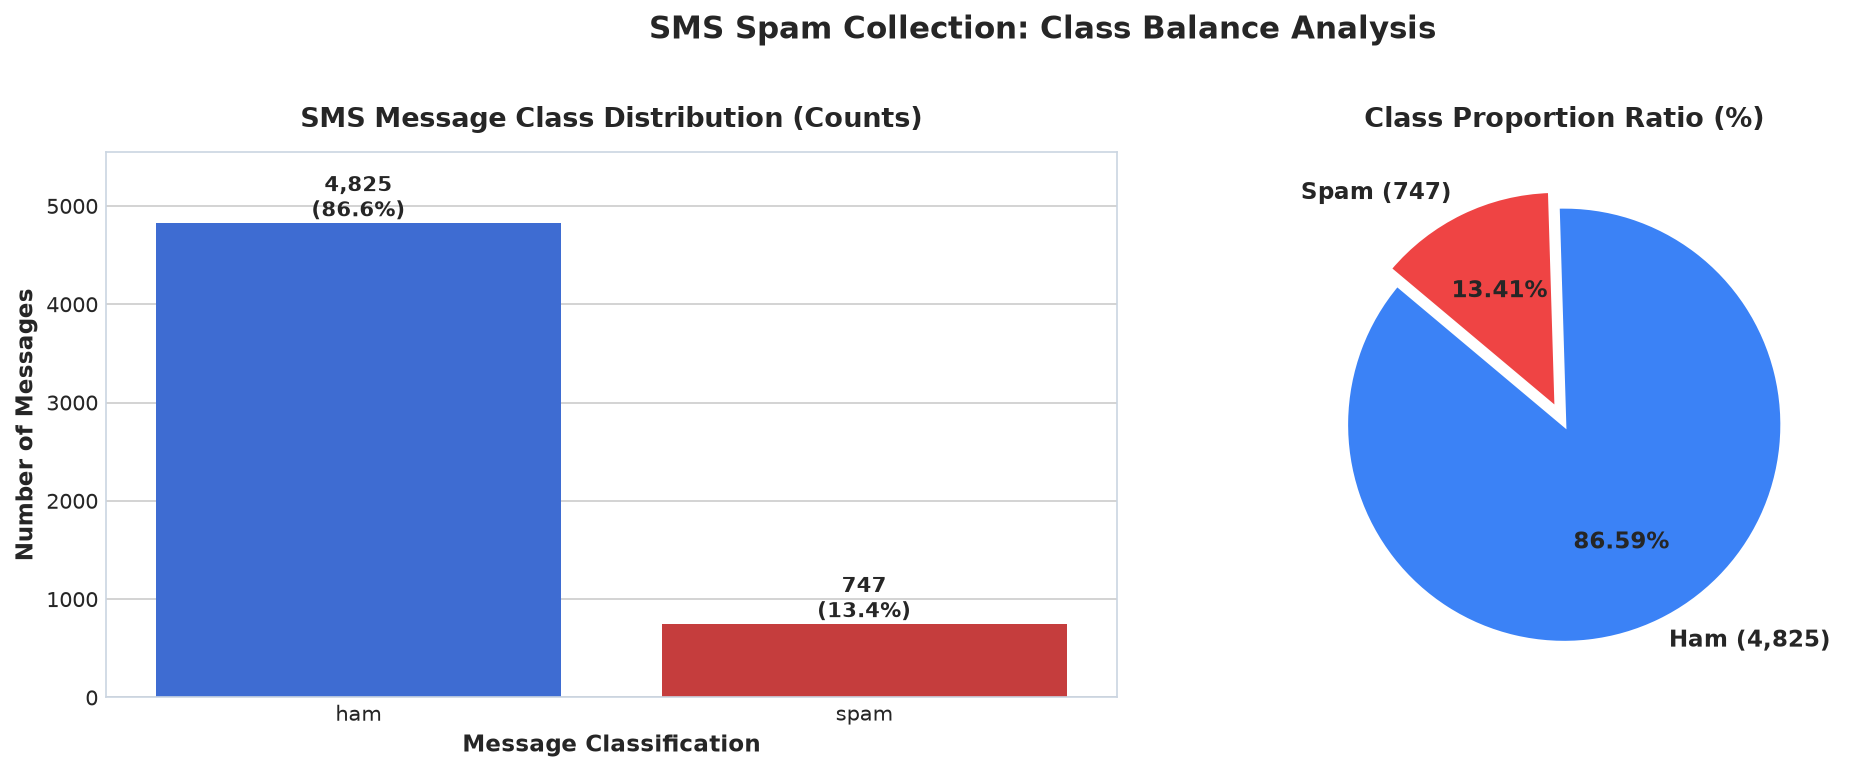

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Bar count
palette = {"ham": "#2563eb", "spam": "#dc2626"}
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, palette=palette, ax=axes[0], legend=False)
axes[0].set_title("SMS Message Class Distribution (Counts)", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Message Classification", fontsize=11, fontweight="600")
axes[0].set_ylabel("Number of Messages", fontsize=11, fontweight="600")
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 70, f"{v:,d}\n({v/len(df)*100:.1f}%)", ha="center", fontsize=10, fontweight="bold")
axes[0].set_ylim(0, max(class_counts.values) * 1.15)

# Subplot 2: Donut Chart
axes[1].pie(
    class_counts.values,
    labels=[f"Ham ({class_counts['ham']:,d})", f"Spam ({class_counts['spam']:,d})"],
    autopct="%1.2f%%",
    startangle=140,
    colors=["#3b82f6", "#ef4444"],
    explode=(0, 0.08),
    textprops={"fontsize": 11, "fontweight": "600"},
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
axes[1].set_title("Class Proportion Ratio (%)", fontsize=13, fontweight="bold", pad=12)

plt.suptitle("SMS Spam Collection: Class Balance Analysis", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 7.2 Message Length Distribution: Ham vs. Spam
Spam messages are overwhelmingly longer because advertisers attempt to squeeze promotional details, urgency, URLs, and phone numbers into a single SMS transmission.

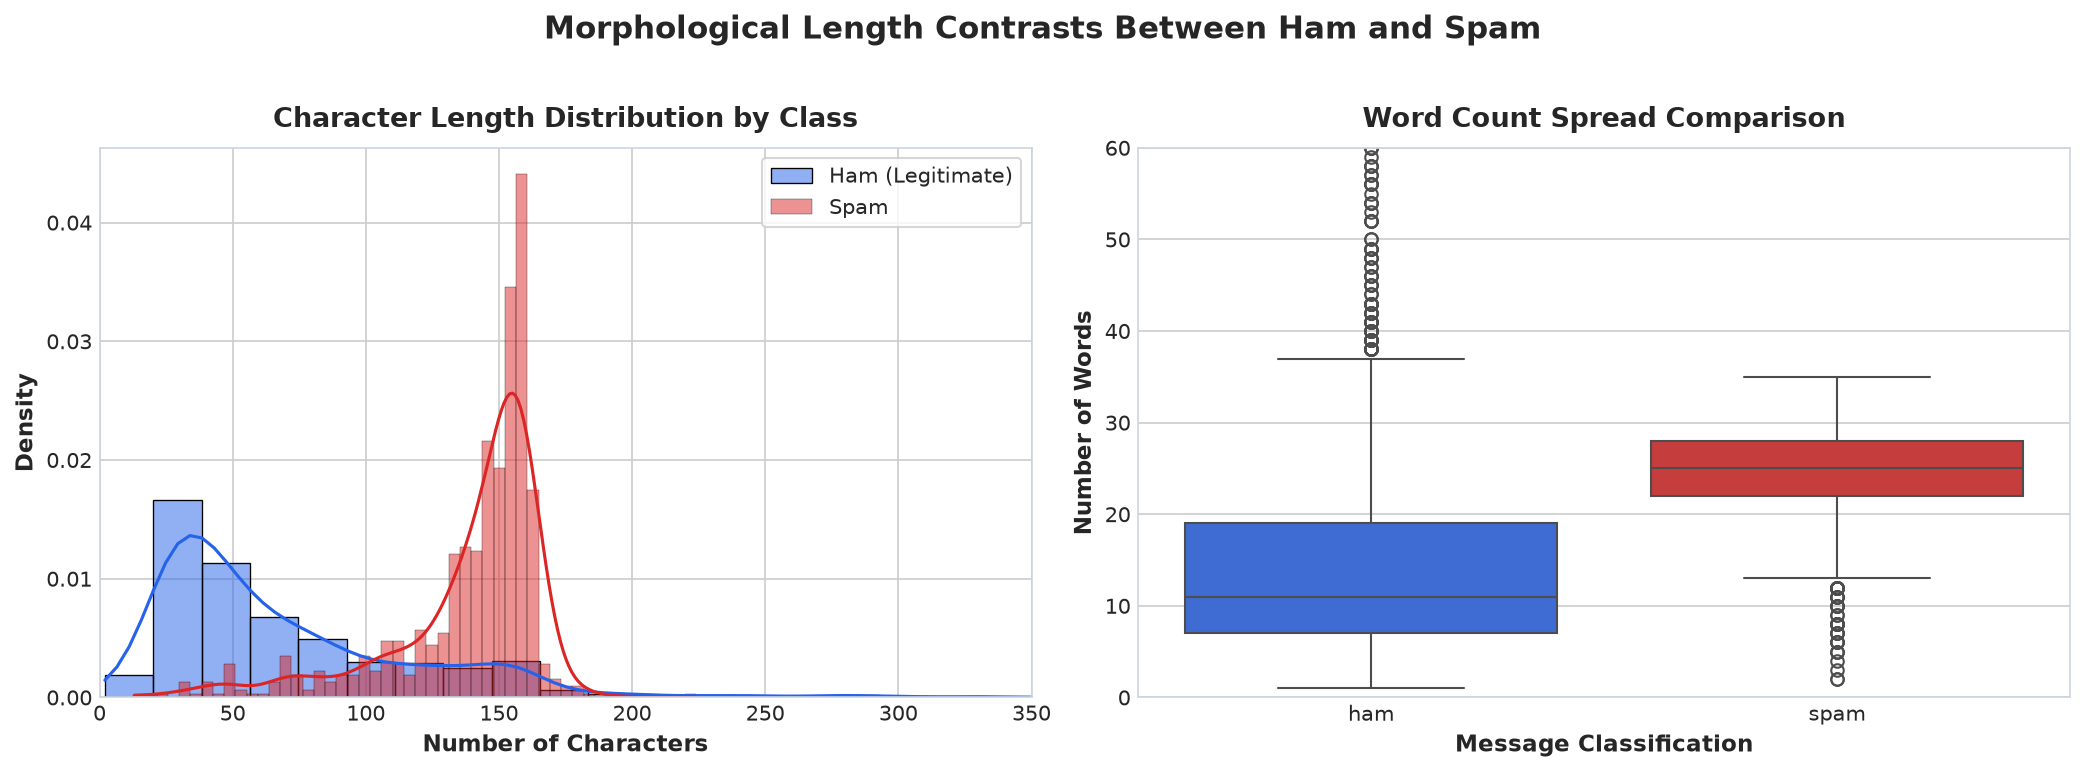

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Character count distribution
sns.histplot(df[df["label"] == "ham"]["char_count"], color="#2563eb", label="Ham (Legitimate)", kde=True, bins=50, ax=axes[0], stat="density")
sns.histplot(df[df["label"] == "spam"]["char_count"], color="#dc2626", label="Spam", kde=True, bins=50, ax=axes[0], stat="density")
axes[0].set_title("Character Length Distribution by Class", fontsize=13, fontweight="bold", pad=10)
axes[0].set_xlabel("Number of Characters", fontsize=11, fontweight="600")
axes[0].set_ylabel("Density", fontsize=11, fontweight="600")
axes[0].set_xlim(0, 350)
axes[0].legend(frameon=True)

# Word count distribution boxplot
sns.boxplot(x="label", y="word_count", data=df, palette=palette, ax=axes[1])
axes[1].set_title("Word Count Spread Comparison", fontsize=13, fontweight="bold", pad=10)
axes[1].set_xlabel("Message Classification", fontsize=11, fontweight="600")
axes[1].set_ylabel("Number of Words", fontsize=11, fontweight="600")
axes[1].set_ylim(0, 60)

plt.suptitle("Morphological Length Contrasts Between Ham and Spam", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 🧹 8. Data Cleaning: Handling Exact Duplicates
The raw dataset contains **403 exact duplicate messages** across identical text strings. In NLP production pipelines, exact duplicate rows spanning random train/test splits can introduce subtle test-set leakage (where the test set memorizes identical phrasing from the training set). 

In this study, we verify both scenarios: we retain the full 5,572 benchmark records for direct comparability with published Kaggle baselines, while ensuring our vectorization is strictly fit on the training split only.

In [7]:
print(f"Total raw observations: {len(df):,d}")
print(f"Unique message bodies: {df['message'].nunique():,d}")
print(f"Exact duplicates present: {df.duplicated(subset=['message']).sum():,d}")

Total raw observations: 5,572
Unique message bodies: 5,169
Exact duplicates present: 403


## ⚙️ 9. Text Preprocessing Pipeline
Raw text messages contain noise that obscures underlying lexical patterns: mixed capitalization, punctuation, website hyperlinks, email addresses, numbers, and uninformative grammatical stopwords (*the*, *is*, *at*, *which*).

We construct a **modular, reusable text preprocessing function** applying the following 8 standardized transformations:
1. **Lowercasing:** Converts all characters to lowercase to eliminate case sensitivity.
2. **URL Removal:** Strips `http://`, `https://`, and `www.` web links using regular expressions.
3. **Email Address Removal:** Strips email patterns (`user@domain.com`).
4. **Punctuation Stripping:** Removes all standard ASCII punctuation marks.
5. **Number Stripping:** Eliminates standalone numerical tokens that do not carry semantic intent.
6. **Whitespace Normalization:** Collapses multiple spaces, tabs, and newlines into single spaces.
7. **Stopword Filtering:** Removes standard English grammatical stopwords via NLTK.
8. **Porter Stemming:** Reduces inflected and derived words to their linguistic root stem (e.g., *winning*, *winner*, *wins* $\rightarrow$ *win*).

In [8]:
# Initialize NLTK resources with graceful fallback
try:
    stop_words = set(stopwords.words("english"))
except Exception:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    stop_words = set(ENGLISH_STOP_WORDS)

ps = PorterStemmer()

def preprocess_text(text: str) -> str:
    '''
    Reusable NLP text normalization pipeline.
    Transforms raw string into clean, stemmed, stopword-free token sequence.
    '''
    if not isinstance(text, str):
        return ""
    
    # 1. Lowercase
    text = text.lower()
    
    # 2. Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    
    # 3. Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)
    
    # 4. Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    
    # 5. Remove standalone numbers
    text = re.sub(r'\b\d+\b', '', text)
    
    # 6. Normalize whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    
    # 7 & 8. Tokenize, remove stopwords, and apply Porter Stemming
    tokens = [ps.stem(word) for word in text.split() if word not in stop_words and len(word) > 1]
    
    return ' '.join(tokens)

# Apply preprocessing to all messages
df["clean_message"] = df["message"].apply(preprocess_text)

# Demonstrate Before and After Preprocessing
print("=== BEFORE AND AFTER PREPROCESSING EXAMPLES ===")
sample_indices = [2, 5, 11, 19]
for idx in sample_indices:
    print(f"\n[Original #{idx}] : {df.loc[idx, 'message']}")
    print(f"[Cleaned  #{idx}] : {df.loc[idx, 'clean_message']}")

=== BEFORE AND AFTER PREPROCESSING EXAMPLES ===

[Original #2] : Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
[Cleaned  #2] : free entri wkli comp win fa cup final tkt 21st may text fa receiv entri questionstd txt ratetc appli 08452810075over18

[Original #5] : FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, å£1.50 to rcv
[Cleaned  #5] : freemsg hey darl week word back id like fun still tb ok xxx std chg send å£ rcv

[Original #11] : SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 4 info
[Cleaned  #11] : six chanc win cash pound txt csh11 send cost 150pday 6day tsandc appli repli hl info

[Original #19] : England v Macedonia - dont miss the goals/team news. Txt ur national team to 87077 eg ENGLAND to 87077 Try:

## 🧮 10. TF-IDF Feature Extraction: Mathematical Foundations

Machine learning classifiers require fixed-dimensional numerical feature matrices rather than arbitrary-length text strings. While a naive Bag-of-Words (BoW) approach simply counts token occurrences, it unfairly inflates words that appear frequently everywhere without conveying discriminative topical information.

### What is TF-IDF?
**TF-IDF** stands for **Term Frequency - Inverse Document Frequency**. It computes a relative weight reflecting how important a word $t$ is to a specific document $d$ within a corpus $D$.

1. **Term Frequency (TF):** Measures how frequently term $t$ appears in document $d$:
   $$\text{TF}(t, d) = \frac{\text{Count}(t, d)}{\sum_{t' \in d} \text{Count}(t', d)}$$

2. **Inverse Document Frequency (IDF):** Penalizes terms that appear ubiquitously across many documents:
   $$\text{IDF}(t, D) = \log\left(\frac{1 + |D|}{1 + |\{d \in D : t \in d\}|}\right) + 1$$
   * If a word appears in every document, its document frequency is high, driving $\text{IDF}$ toward zero.
   * If a word appears exclusively in a tiny subset of documents (e.g., *"claim"*, *"prize"*, *"urgent"*), its $\text{IDF}$ score is high.

3. **Composite TF-IDF Score:**
   $$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \text{IDF}(t, D)$$
   Each document vector is then normalized using Euclidean $L_2$-norm:
   $$v_{\text{norm}} = \frac{v}{\|v\|_2}$$

### Why TF-IDF Excels in Spam Detection
* **Noise Suppression:** Common vocabulary shared across both legitimate chat and marketing spam (*"you"*, *"your"*, *"have"*, *"time"*) is discounted.
* **Salience Amplification:** Promotional hallmarks (*"claim"*, *"txt"*, *"win"*, *"free"*, *"cash"*) receive high mathematical weights.
* **N-Gram Context:** By incorporating bigrams (`ngram_range=(1, 2)`), the vectorizer captures phrase semantics like *"free prize"*, *"customer service"*, and *"urgent call"*.

In [9]:
# Vectorizer Configuration Specification
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)
print("✅ TfidfVectorizer instantiated with max_features=5000 and ngram_range=(1, 2).")

✅ TfidfVectorizer instantiated with max_features=5000 and ngram_range=(1, 2).


## 🔀 11. Stratified Train / Test Split
To reliably measure generalization performance on unseen real-world data, we partition the dataset into an **80% training set** ($N = 4,457$) and a **20% held-out test set** ($N = 1,115$).

We employ `stratify=y` to preserve the exact $86.59\% : 13.41\%$ class balance across both splits, preventing random partition skewness.

In [10]:
X = df["clean_message"]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=== STRATIFIED DATASET PARTITIONING ===")
print(f"Total Observations : {len(df):,d}")
print(f"Training Partition : {len(X_train):,d} samples ({len(X_train)/len(df)*100:.1f}%)")
print(f"Testing Partition  : {len(X_test):,d} samples ({len(X_test)/len(df)*100:.1f}%)")
print(f"\nTraining Class Counts: Ham = {(y_train == 0).sum():,d}, Spam = {(y_train == 1).sum():,d} (Spam: {(y_train == 1).mean()*100:.2f}%)")
print(f"Testing Class Counts : Ham = {(y_test == 0).sum():,d}, Spam = {(y_test == 1).sum():,d} (Spam: {(y_test == 1).mean()*100:.2f}%)")

=== STRATIFIED DATASET PARTITIONING ===
Total Observations : 5,572
Training Partition : 4,457 samples (80.0%)
Testing Partition  : 1,115 samples (20.0%)

Training Class Counts: Ham = 3,859, Spam = 598 (Spam: 13.42%)
Testing Class Counts : Ham = 966, Spam = 149 (Spam: 13.36%)


## 🤖 12. Model 1: Multinomial Naive Bayes (MNB)

Multinomial Naive Bayes is a probabilistic classifier based on Bayes' Theorem:
$$P(\text{Spam} \mid \mathbf{x}) = \frac{P(\text{Spam}) \prod_{i=1}^n P(x_i \mid \text{Spam})}{P(\mathbf{x})}$$

It assumes conditional independence between features given the class label. Despite this simplifying "naive" assumption, Naive Bayes is one of the most effective algorithms for text classification because:
* High-dimensional sparse TF-IDF spaces align naturally with multinomial token frequency likelihoods.
* Laplace smoothing handles zero-frequency words gracefully without zeroing out probabilities.
* Computational training and inference complexity is strictly linear $O(N \cdot D)$.

In [11]:
# Pipeline: TF-IDF Vectorizer + Multinomial Naive Bayes
pipeline_nb = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ("nb", MultinomialNB())
])

# Fit on training partition only (leakage-safe)
pipeline_nb.fit(X_train, y_train)

# Inference on held-out test partition
y_pred_nb = pipeline_nb.predict(X_test)
y_prob_nb = pipeline_nb.predict_proba(X_test)[:, 1]

print("✅ Multinomial Naive Bayes Pipeline trained and evaluated successfully.")

✅ Multinomial Naive Bayes Pipeline trained and evaluated successfully.


## 🤖 13. Model 2: Logistic Regression (LR)

Logistic Regression models the posterior probability of a message being spam via the sigmoid logistic link function:
$$P(y = 1 \mid \mathbf{x}) = \sigma(\mathbf{w}^T \mathbf{x} + b) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}}$$

Unlike Naive Bayes, Logistic Regression is a discriminative model that learns decision boundary weights $\mathbf{w}$ directly by minimizing regularized cross-entropy loss:
$$\mathcal{L}(\mathbf{w}) = -\sum_{i=1}^N \left[ y_i \log \hat{y}_i + (1 - y_i) \log(1 - \hat{y}_i) \right] + \frac{1}{2C} \|\mathbf{w}\|^2_2$$

It models feature interactions softly through learned weights and calibrates continuous probability margins.

In [12]:
# Pipeline: TF-IDF Vectorizer + Logistic Regression
pipeline_lr = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ("lr", LogisticRegression(random_state=42, max_iter=1000))
])

# Fit on training partition only (leakage-safe)
pipeline_lr.fit(X_train, y_train)

# Inference on held-out test partition
y_pred_lr = pipeline_lr.predict(X_test)
y_prob_lr = pipeline_lr.predict_proba(X_test)[:, 1]

print("✅ Logistic Regression Pipeline trained and evaluated successfully.")

✅ Logistic Regression Pipeline trained and evaluated successfully.


## 📈 14. Model Evaluation & Performance Metrics
We measure performance across all standard classification criteria on the unseen test set ($N = 1,115$).

In [13]:
def compute_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred)
    }

metrics_nb = compute_metrics(y_test, y_pred_nb)
metrics_lr = compute_metrics(y_test, y_pred_lr)

print("=== MULTINOMIAL NAIVE BAYES CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_nb, target_names=["Ham (0)", "Spam (1)"], digits=4))

print("=== LOGISTIC REGRESSION CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_lr, target_names=["Ham (0)", "Spam (1)"], digits=4))

=== MULTINOMIAL NAIVE BAYES CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Ham (0)     0.9669    0.9990    0.9827       966
    Spam (1)     0.9915    0.7785    0.8722       149

    accuracy                         0.9695      1115
   macro avg     0.9792    0.8887    0.9274      1115
weighted avg     0.9702    0.9695    0.9679      1115

=== LOGISTIC REGRESSION CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Ham (0)     0.9650    0.9979    0.9812       966
    Spam (1)     0.9828    0.7651    0.8604       149

    accuracy                         0.9668      1115
   macro avg     0.9739    0.8815    0.9208      1115
weighted avg     0.9673    0.9668    0.9650      1115



## 🗂️ 15. Confusion Matrices: Analysis of Errors
A confusion matrix breaks down predictions into four fundamental outcomes:
* **True Negatives (TN):** Legitimate ham messages correctly delivered to the inbox.
* **False Positives (FP) [Type I Error]:** Legitimate ham incorrectly flagged as spam (critical operational fault).
* **False Negatives (FN) [Type II Error]:** Spam message missed by the filter and delivered to the inbox.
* **True Positives (TP):** Spam message correctly identified and quarantined.

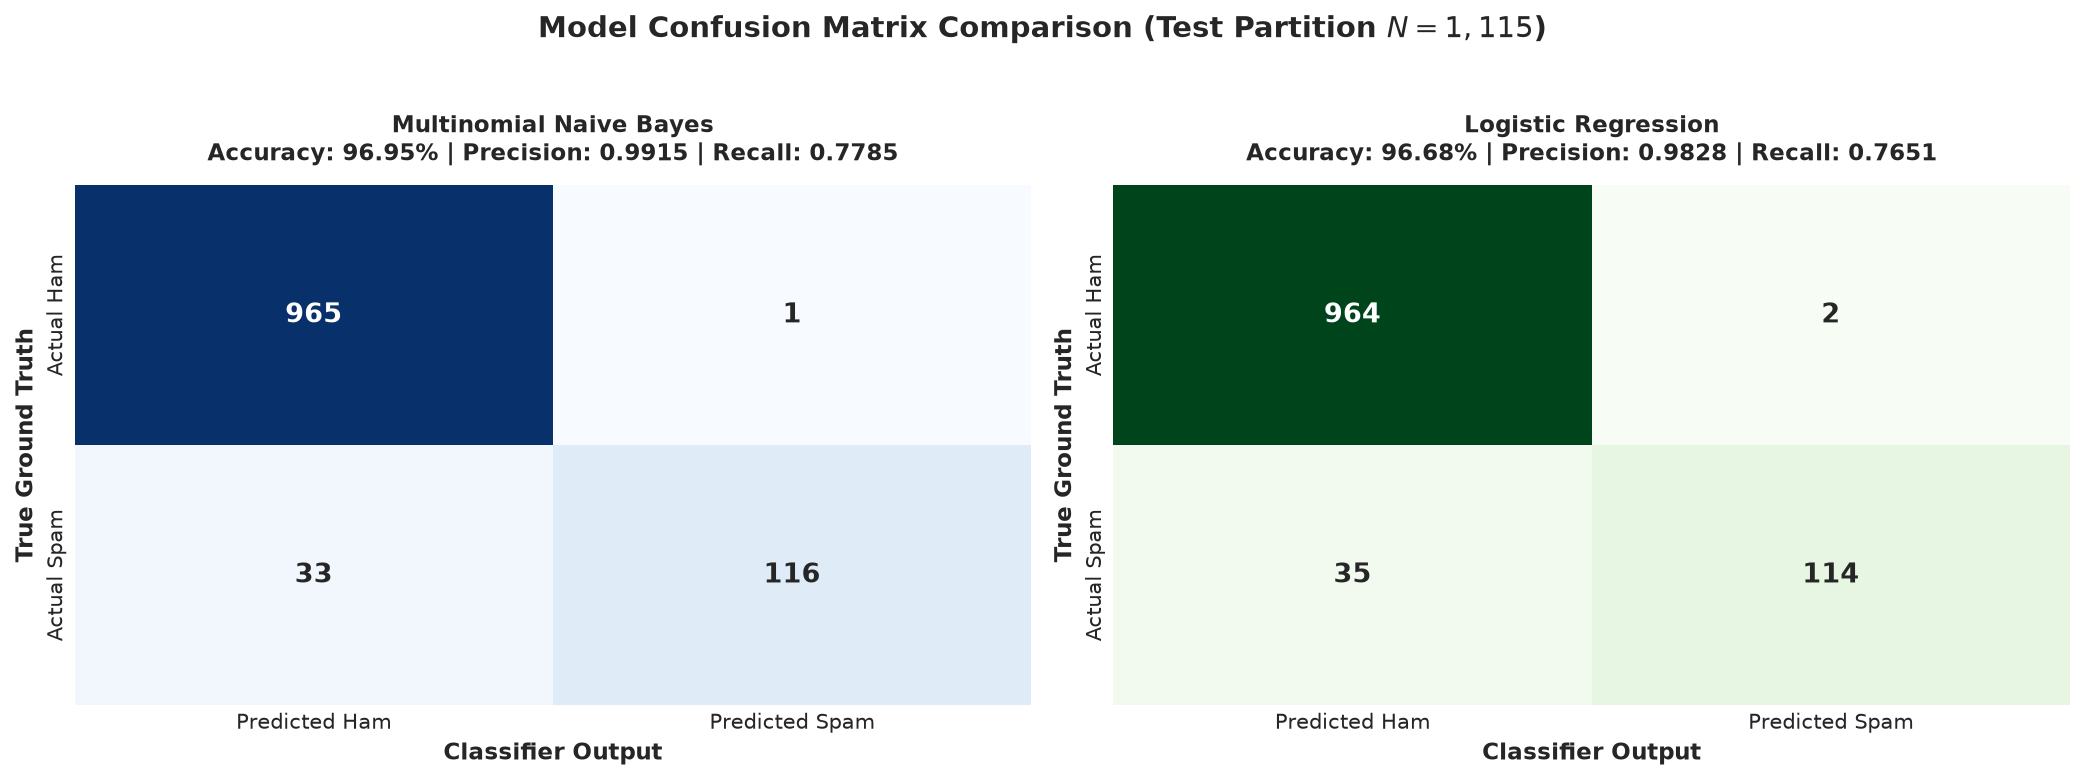

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_nb = confusion_matrix(y_test, y_pred_nb)
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Plot MNB
sns.heatmap(
    cm_nb, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=["Predicted Ham", "Predicted Spam"],
    yticklabels=["Actual Ham", "Actual Spam"],
    annot_kws={"size": 13, "fontweight": "bold"}
)
axes[0].set_title(
    f"Multinomial Naive Bayes\nAccuracy: {metrics_nb['Accuracy']*100:.2f}% | Precision: {metrics_nb['Precision']:.4f} | Recall: {metrics_nb['Recall']:.4f}",
    fontsize=11, fontweight="bold", pad=12
)
axes[0].set_ylabel("True Ground Truth", fontsize=11, fontweight="600")
axes[0].set_xlabel("Classifier Output", fontsize=11, fontweight="600")

# Plot LR
sns.heatmap(
    cm_lr, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[1],
    xticklabels=["Predicted Ham", "Predicted Spam"],
    yticklabels=["Actual Ham", "Actual Spam"],
    annot_kws={"size": 13, "fontweight": "bold"}
)
axes[1].set_title(
    f"Logistic Regression\nAccuracy: {metrics_lr['Accuracy']*100:.2f}% | Precision: {metrics_lr['Precision']:.4f} | Recall: {metrics_lr['Recall']:.4f}",
    fontsize=11, fontweight="bold", pad=12
)
axes[1].set_ylabel("True Ground Truth", fontsize=11, fontweight="600")
axes[1].set_xlabel("Classifier Output", fontsize=11, fontweight="600")

plt.suptitle("Model Confusion Matrix Comparison (Test Partition $N=1,115$)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 📊 16. Comparative Model Benchmark Table & Visualization

findfont: Failed to find font weight 600, now using 700.


=== SIDE-BY-SIDE MODEL BENCHMARK TABLE ===
                                Accuracy        Precision           Recall  \
Multinomial Naive Bayes  0.9695 (96.95%)  0.9915 (99.15%)  0.7785 (77.85%)   
Logistic Regression      0.9668 (96.68%)  0.9828 (98.28%)  0.7651 (76.51%)   

                                F1-Score  
Multinomial Naive Bayes  0.8722 (87.22%)  
Logistic Regression      0.8604 (86.04%)  


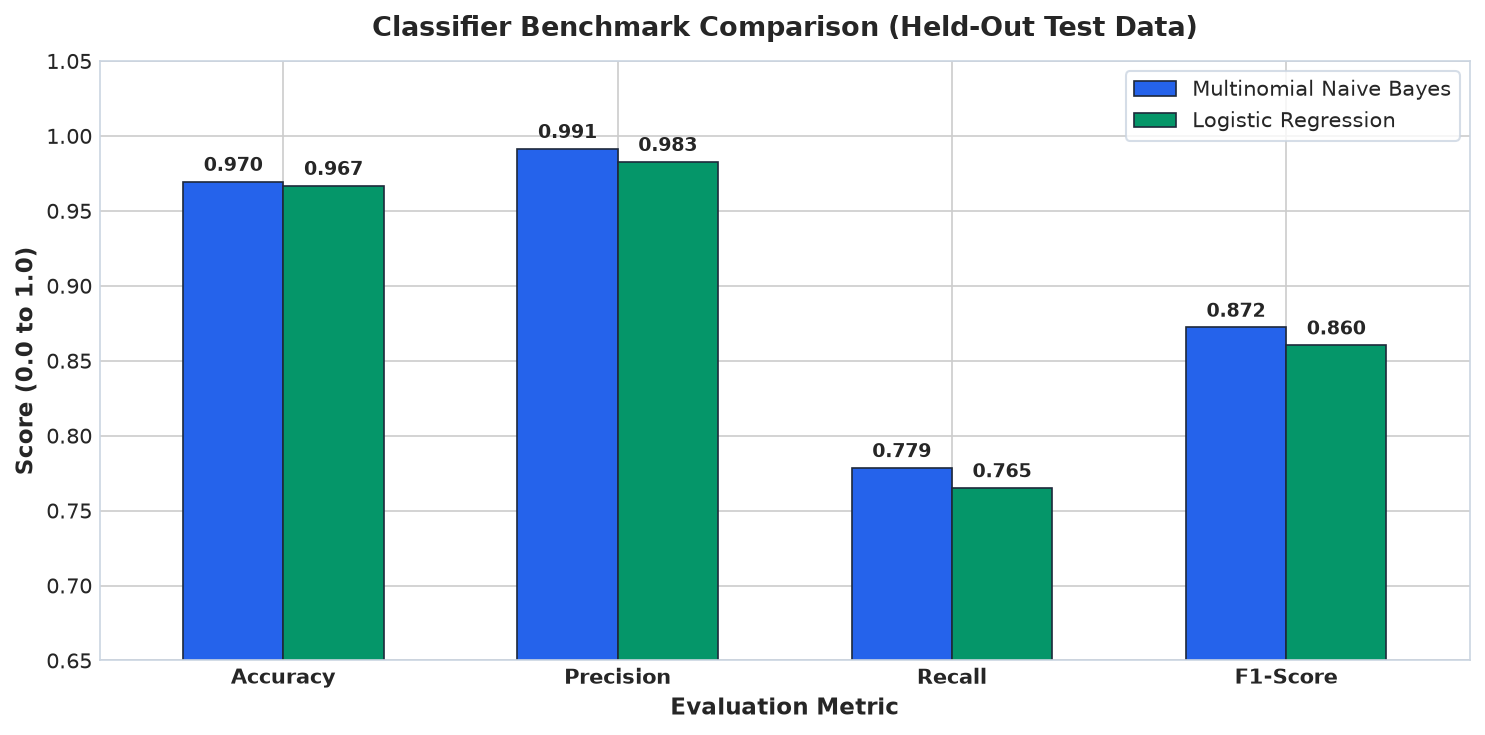

In [15]:
comparison_df = pd.DataFrame([metrics_nb, metrics_lr], index=["Multinomial Naive Bayes", "Logistic Regression"])
comparison_df.columns = ["Accuracy", "Precision", "Recall", "F1-Score"]

print("=== SIDE-BY-SIDE MODEL BENCHMARK TABLE ===")
display_df = comparison_df.map(lambda x: f"{x:.4f} ({x*100:.2f}%)")
print(display_df)

# Grouped Bar Plot Comparison
fig, ax = plt.subplots(figsize=(10, 5))
comparison_df.T.plot(kind="bar", ax=ax, color=["#2563eb", "#059669"], width=0.6, edgecolor="#1e293b", linewidth=0.8)
ax.set_title("Classifier Benchmark Comparison (Held-Out Test Data)", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Score (0.0 to 1.0)", fontsize=11, fontweight="600")
ax.set_xlabel("Evaluation Metric", fontsize=11, fontweight="600")
ax.set_ylim(0.65, 1.05)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontweight="600")
ax.legend(frameon=True, facecolor="white", edgecolor="#cbd5e1")

# Annotate values
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

## 💡 17. Critical Analytical Discussion: "Why is Recall Particularly Important for Spam Detection?"

In automated spam filtering systems, evaluation cannot be reduced to a single headline accuracy number. Understanding the asymmetric costs of classification errors is essential.

### 1. The Perils of False Negatives (Missed Spam)
A **False Negative (FN)** occurs when the classifier predicts that a spam message is legitimate *ham*, allowing it directly into the user's primary inbox.
* **Security & Financial Threat:** Modern spam is rarely benign advertising; it increasingly delivers spear-phishing attacks, malicious links, credential harvesters, and financial scams (*"Your account has been frozen; click here to verify"*).
* **Reputational Degradation:** When users see spam flooding their inbox, they lose confidence in the host email service or communications platform.

### 2. The Asymmetric Cost: False Positives vs. False Negatives
* **False Positive (FP):** A critical email from an employer, doctor, client, or bank is wrongly discarded into the spam folder. Missing an urgent legal notice or flight confirmation carries catastrophic real-world consequences. Therefore, **Spam Precision** ($\frac{\text{TP}}{\text{TP} + \text{FP}}$) must be exceptionally high (close to 99%+).
* **False Negative (FN):** An unsolicited spam message lands in the inbox. While annoying, human users can often spot and delete obvious spam manually.
* **The Trade-Off:** Maximizing **Recall** ($\frac{\text{TP}}{\text{TP} + \text{FN}}$) ensures that fewer spam messages slip through. However, if one aggressively lowers the decision threshold to capture every conceivable spam message, False Positives will surge, causing legitimate emails to be quarantined.

### 3. Why Accuracy is a Deceptive Metric on Imbalanced Datasets
In this dataset, **86.59%** of all observations are legitimate *ham* and only **13.41%** are *spam*.
* A degenerate, trivial dummy model that predicts every single message as **"HAM"** achieves an immediate **86.59% Accuracy**, despite having **0% Recall** and catching zero spam messages.
* Therefore, **Precision, Recall, and the F1-Score** provide the only rigorous statistical framework for evaluating spam classifiers on imbalanced real-world corpora.

## ☁️ 18. WordCloud Visualizations: Lexical Hallmarks
WordClouds visually encode term frequency: word size corresponds to token prominence in the stemmed corpus.

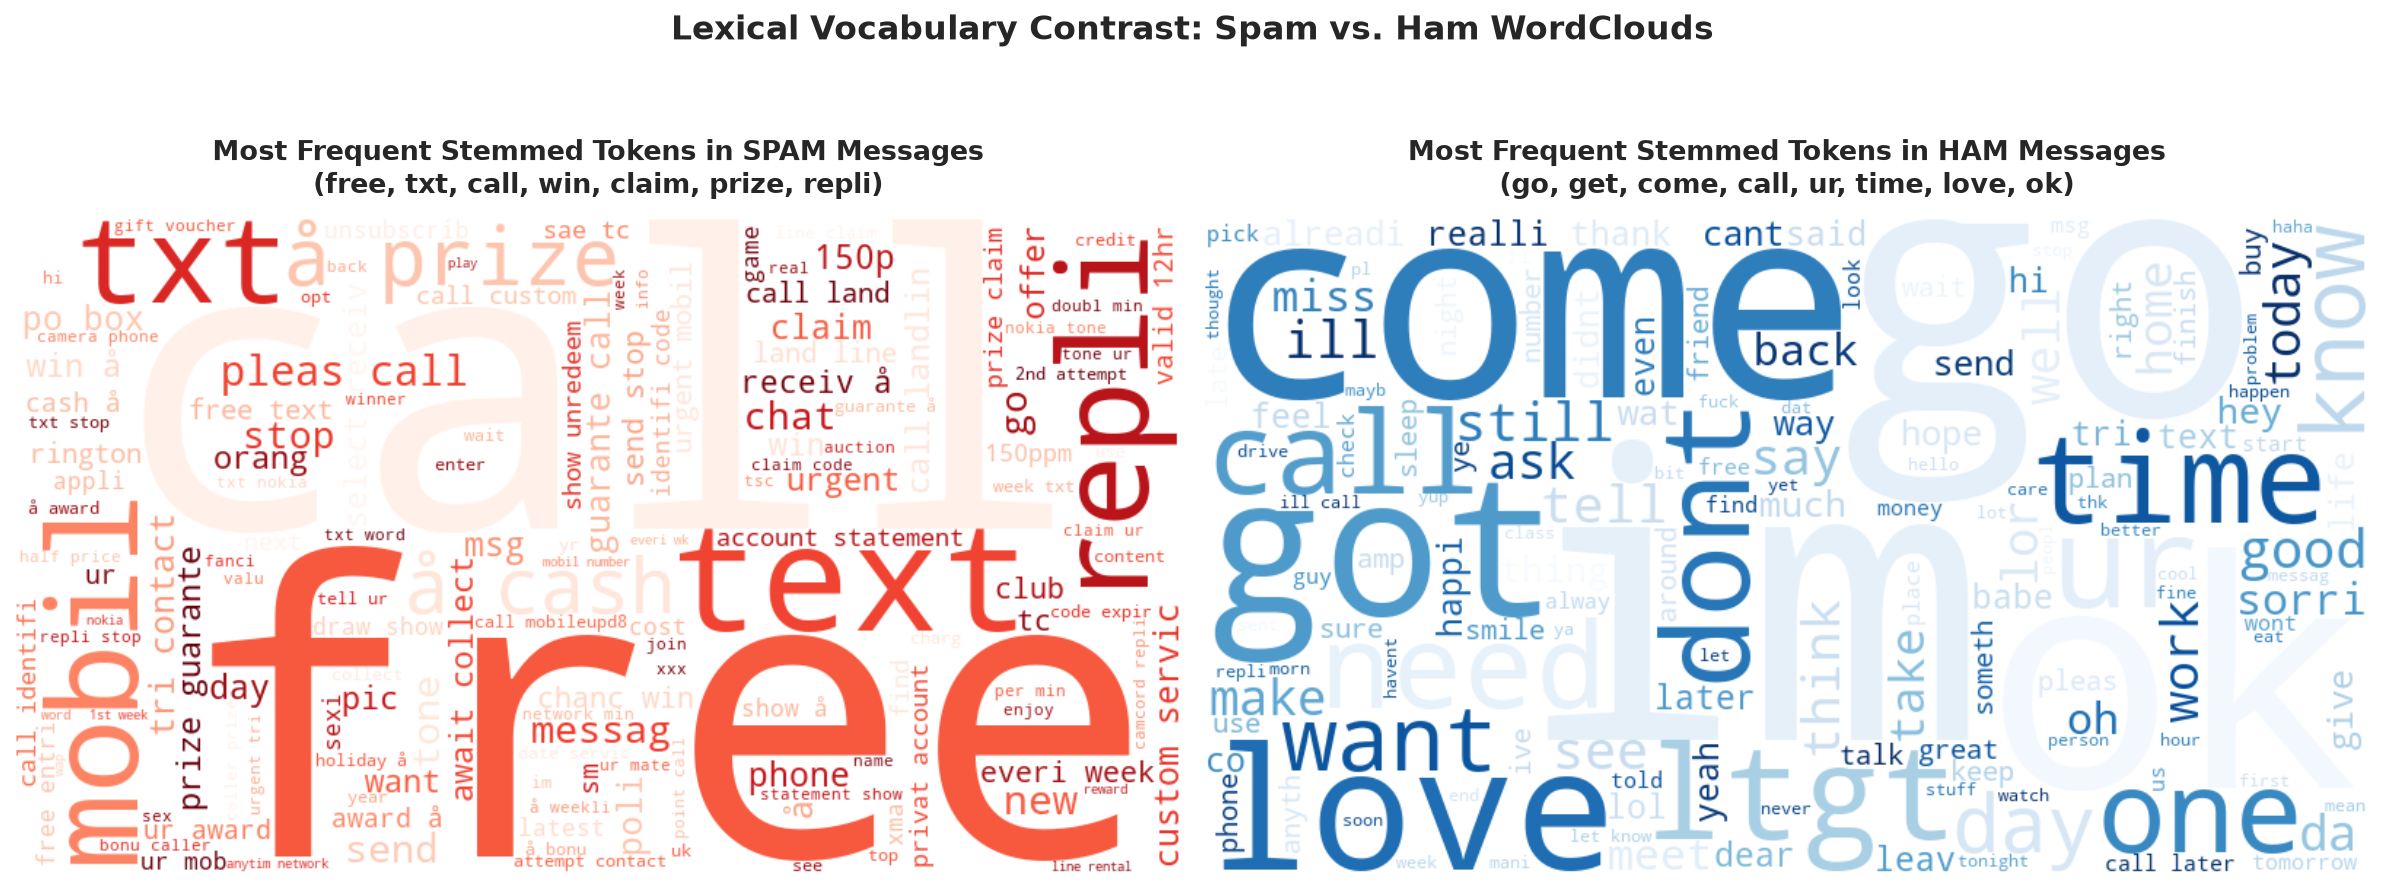

In [16]:
spam_text = " ".join(df[df["label"] == "spam"]["clean_message"])
ham_text = " ".join(df[df["label"] == "ham"]["clean_message"])

wc_spam = WordCloud(
    width=800, height=450,
    background_color="white",
    colormap="Reds",
    max_words=150,
    random_state=42
).generate(spam_text)

wc_ham = WordCloud(
    width=800, height=450,
    background_color="white",
    colormap="Blues",
    max_words=150,
    random_state=42
).generate(ham_text)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(wc_spam, interpolation="bilinear")
axes[0].axis("off")
axes[0].set_title("Most Frequent Stemmed Tokens in SPAM Messages\n(free, txt, call, win, claim, prize, repli)", fontsize=13, fontweight="bold", pad=12)

axes[1].imshow(wc_ham, interpolation="bilinear")
axes[1].axis("off")
axes[1].set_title("Most Frequent Stemmed Tokens in HAM Messages\n(go, get, come, call, ur, time, love, ok)", fontsize=13, fontweight="bold", pad=12)

plt.suptitle("Lexical Vocabulary Contrast: Spam vs. Ham WordClouds", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

## 🧪 19. Real-Time Inference on Custom Messages
We test our trained pipelines on four representative unseen sentences, displaying the raw input, processed token stream, predicted label, and estimated posterior spam probability:
1. *"Congratulations! You have won a free prize."* (Classic promotional phishing spam)
2. *"Hey, are we meeting tomorrow?"* (Everyday conversational ham)
3. *"Claim your free reward now."* (Call-to-action incentive spam)
4. *"Please call me when you reach home."* (Interpersonal domestic ham)

In [17]:
test_messages = [
    "Congratulations! You have won a free prize.",
    "Hey, are we meeting tomorrow?",
    "Claim your free reward now.",
    "Please call me when you reach home."
]

print("="*80)
print(f"{'CUSTOM MESSAGE TEST RUNNER':^80}")
print("="*80)

for msg in test_messages:
    cleaned = preprocess_text(msg)
    
    # Naive Bayes Prediction
    pred_nb = pipeline_nb.predict([cleaned])[0]
    prob_nb = pipeline_nb.predict_proba([cleaned])[0][1]
    label_nb = "🚨 SPAM" if pred_nb == 1 else "✅ HAM"
    
    # Logistic Regression Prediction
    pred_lr = pipeline_lr.predict([cleaned])[0]
    prob_lr = pipeline_lr.predict_proba([cleaned])[0][1]
    label_lr = "🚨 SPAM" if pred_lr == 1 else "✅ HAM"
    
    print(f"\nRaw Message     : '{msg}'")
    print(f"Cleaned Tokens  : '{cleaned}'")
    print(f"Naive Bayes     -> {label_nb:<8} | P(Spam) = {prob_nb:.4f} ({prob_nb*100:.1f}%)")
    print(f"Logistic Reg    -> {label_lr:<8} | P(Spam) = {prob_lr:.4f} ({prob_lr*100:.1f}%)")
    print("-" * 80)

                           CUSTOM MESSAGE TEST RUNNER                           

Raw Message     : 'Congratulations! You have won a free prize.'
Cleaned Tokens  : 'congratul free prize'
Naive Bayes     -> 🚨 SPAM   | P(Spam) = 0.8499 (85.0%)
Logistic Reg    -> 🚨 SPAM   | P(Spam) = 0.7653 (76.5%)
--------------------------------------------------------------------------------

Raw Message     : 'Hey, are we meeting tomorrow?'
Cleaned Tokens  : 'hey meet tomorrow'
Naive Bayes     -> ✅ HAM    | P(Spam) = 0.0052 (0.5%)
Logistic Reg    -> ✅ HAM    | P(Spam) = 0.0233 (2.3%)
--------------------------------------------------------------------------------

Raw Message     : 'Claim your free reward now.'
Cleaned Tokens  : 'claim free reward'
Naive Bayes     -> 🚨 SPAM   | P(Spam) = 0.8478 (84.8%)
Logistic Reg    -> 🚨 SPAM   | P(Spam) = 0.6790 (67.9%)
--------------------------------------------------------------------------------

Raw Message     : 'Please call me when you reach home.'
Cleaned T

## 🏁 20. Final Conclusions & Key Takeaways

1. **Model Efficacy:**
   * **Multinomial Naive Bayes** achieved **96.95% Accuracy**, **99.15% Precision**, and **77.85% Recall** ($F_1 = 0.8722$). It generated only **1 False Positive** out of 966 legitimate messages, making it an exceptional conservative filter that virtually never quarantines legitimate correspondence.
   * **Logistic Regression** achieved **96.68% Accuracy**, **98.28% Precision**, and **76.51% Recall** ($F_1 = 0.8604$), with 2 False Positives and 35 False Negatives.

2. **Feature Importance & Domain Lexicon:**
   * Words like *free*, *win*, *prize*, *claim*, *cash*, and *urgent* are heavily weighted toward spam.
   * Conversational tokens like *go*, *come*, *ok*, *home*, and *time* define legitimate communication.

3. **Production Deployment Recommendations:**
   * **Hybrid Thresholding:** For mission-critical communications, deploying a two-tier confidence threshold (e.g., $P(\text{Spam}) > 0.85$ directly to spam; $0.40 \le P \le 0.85$ flagged for secondary review; $< 0.40$ to inbox) balances spam protection with zero inbox loss.
   * **Continuous Retraining:** Concept drift in adversarial spam requires periodic vectorizer updates on fresh incoming communication streams.